# Khám phá dữ liệu WESAD 

Phạm vi: 21 thống kê raw từ ECG, EDA và Resp ngực, 700 Hz; cửa sổ
60 giây, bước 5 giây, nhãn đa số ít nhất 90%. Chưa phải bộ HRV/SCR
hoặc bộ cảm biến ngực/cổ tay kết hợp.

Đặt notebook tại `wesad-stress-detection/notebooks/01_eda.ipynb`.
Chọn kernel `.venv`, rồi Restart Kernel → Run All. Cần numpy, pandas,
matplotlib, IPython; PyYAML nếu đọc đường dẫn raw từ configs/local.yaml.

Bảng đầu vào: `data/features/chest_raw_stats_majority_v1/all_subjects.csv`.
Nếu chưa có, chạy từ gốc `wesad-stress-detection`:

```powershell
python scripts/extract_features.py --config configs/features_smoke.yaml --local configs/local.yaml --subjects S2 S3 S4 S5 S6 S7 S8 S9 S10 S11 S13 S14 S15 S16 S17 --resume
```

Notebook chỉ phân tích bảng đã trích xuất, không chuyển CSV 60/60 thành
60/5. Cần trích lại từ PKL để tạo các cửa sổ bước 5 giây.
Đầu ra được lưu riêng tại `reports/tables/eda_step5/` và
`reports/figures/eda_step5/`. Kết quả, hình và nhận xét 60/60 cũ đã được
gỡ khỏi bản này; phần nhận xét mới được tính tự động ở mục 9 khi chạy.


## 1. Thiết lập đường dẫn và phạm vi


In [ ]:
from pathlib import Path
import hashlib
import json
import warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Chỉ sửa biến này nếu notebook không tìm được gốc dự án.
PROJECT_ROOT_OVERRIDE = None  # Hoặc Path(r"C:/duong/dan/wesad-stress-detection")  
if PROJECT_ROOT_OVERRIDE:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    candidates += [p / 'wesad-stress-detection' for p in list(candidates)]
    PROJECT_ROOT = next((p for p in candidates if (p / 'src/wesad').is_dir() and (p / 'configs').is_dir()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Không tìm thấy gốc dự án. Hãy sửa PROJECT_ROOT_OVERRIDE ở trên.')

# Chỉ sửa override nếu feature nằm ngoài thư mục mặc định của dự án.
FEATURE_DIR_OVERRIDE = None  # Ví dụ: r'D:/shared/chest_raw_stats_majority_v1'
FEATURE_DIR = (Path(FEATURE_DIR_OVERRIDE).expanduser().resolve() if FEATURE_DIR_OVERRIDE
               else PROJECT_ROOT / 'data/features/chest_raw_stats_majority_v1')
WINDOW_SECONDS = 60
STEP_SECONDS = 5
MIN_LABEL_FRACTION = 0.90
FEATURE_PATH = FEATURE_DIR / 'all_subjects.csv'
TABLE_DIR = PROJECT_ROOT / 'notebooks/reports/tables/eda_step5'
FIG_DIR = PROJECT_ROOT / 'notebooks/reports/figures/eda_step5'
for folder in (TABLE_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
EXPECTED_SUBJECTS = [f'S{i}' for i in [2,3,4,5,6,7,8,9,10,11,13,14,15,16,17]]
LABEL_NAMES = {1:'Baseline', 2:'Stress', 3:'Amusement'}
COLORS = ['#4c78a8', '#e45756', '#72b7b2']
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})

def save_table(frame, name, index=False):
    frame.to_csv(TABLE_DIR / name, index=index, encoding='utf-8-sig')

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 2. Nạp dữ liệu và xác minh bộ 60/5

Kiểm tra 8 metadata, 21 feature, độ dài 60 giây, lưới bước 5 giây,
nhãn đa số ≥90% và ánh xạ nhị phân. Cửa sổ được phép chồng lấn.
Khoảng cách giữa hai cửa sổ giữ lại có thể là 10, 15,... giây vì cửa sổ
trung gian bị loại. Nếu thiếu config.json, lưới và tỷ lệ nhãn trong CSV
không đủ để chứng minh cấu hình tạo dữ liệu hoặc tính lại nhãn từ PKL.


In [4]:
if not FEATURE_PATH.is_file():
    raise FileNotFoundError(f'Chưa có {FEATURE_PATH}. Chạy extractor 60/5 ở hướng dẫn đầu notebook hoặc sửa FEATURE_DIR_OVERRIDE.')
df = pd.read_csv(FEATURE_PATH, dtype={'subject_id':str, 'window_id':str})
if df.empty or df.columns.duplicated().any():
    raise ValueError('Bảng rỗng hoặc có cột trùng.')
required = ['subject_id','window_id','start_s','end_s','label_original',
            'label_binary','label_fraction','quality_flag']
feature_cols = [f'{sensor}_{stat}' for sensor in ['ecg','eda','resp']
                for stat in ['mean','std','min','max','rms','iqr','range']]
missing_cols = sorted(set(required + feature_cols) - set(df.columns))
if missing_cols:
    raise ValueError(f'Thiếu cột: {missing_cols}. Cần bảng 60/5 mới từ extractor; không dùng CSV 60/60 cũ.')
if df[required].isna().any().any():
    raise ValueError('Metadata bắt buộc bị thiếu.')
extra_columns = sorted(set(df.columns) - set(required + feature_cols))
if extra_columns:
    warnings.warn(f'Có cột ngoài bộ raw-stat: {extra_columns}. Notebook chỉ phân tích 21 feature ECG/EDA/Resp.')
for col in feature_cols + ['start_s','end_s','label_original','label_binary','label_fraction']:
    df[col] = pd.to_numeric(df[col], errors='raise')
if not df.label_original.isin([1,2,3]).all():
    raise ValueError('Nhãn ba lớp chỉ nhận 1, 2, 3.')
if not np.array_equal(df.label_binary.to_numpy(), (df.label_original == 2).astype(int).to_numpy()):
    raise ValueError('label_binary phải là 2→1, 1/3→0.')
if not np.isfinite(df[['start_s','end_s','label_fraction']].to_numpy()).all():
    raise ValueError('Thời gian hoặc tỷ lệ nhãn không hữu hạn.')
if not df.label_fraction.between(MIN_LABEL_FRACTION - 1e-12, 1 + 1e-12).all():
    raise ValueError('Có label_fraction ngoài [0.90, 1].')
if (df.start_s < 0).any() or not np.isclose(df.end_s - df.start_s, WINDOW_SECONDS, atol=1e-6, rtol=0).all():
    raise ValueError('Thời gian không hợp lệ hoặc cửa sổ không dài 60 giây.')
if not np.isclose(df.start_s / STEP_SECONDS, np.round(df.start_s / STEP_SECONDS), atol=1e-6, rtol=0).all():
    raise ValueError('Có cửa sổ ngoài lưới 5 giây.')
ordered = df.sort_values(['subject_id','start_s'])
gaps = ordered.groupby('subject_id').start_s.diff().dropna()
if (gaps < STEP_SECONDS - 1e-6).any():
    raise ValueError('Có thời điểm bắt đầu trùng hoặc cách nhau dưới 5 giây trong cùng subject.')

processing = None
if (FEATURE_DIR / 'config.json').is_file():
    snapshot = json.loads((FEATURE_DIR / 'config.json').read_text(encoding='utf-8'))
    processing = snapshot.get('processing', snapshot)
    expected_config = {'device':'chest', 'sensors':['ECG','EDA','Resp'],
                       'sampling_rate_hz':700, 'labels':[1,2,3],
                       'window_seconds':60, 'step_seconds':5,
                       'label_rule':'majority', 'min_label_fraction':0.90,
                       'feature_version':'chest_raw_stats_majority_v1'}
    for key, expected in expected_config.items():
        if processing.get(key) != expected:
            raise ValueError(f'config.json: {key}={processing.get(key)!r}, cần {expected!r}.')
    if processing.get('subject_processor'):
        raise ValueError('Gói dùng processor riêng; notebook này chỉ xác minh bộ raw-stat mặc định.')
    print('Đã đối chiếu metadata: 60/5, majority ≥90%, ECG/EDA/Resp raw-stat.')
else:
    warnings.warn('Thiếu config.json: chỉ kiểm tra lưới 5 giây và label_fraction trong CSV; chưa xác minh được cấu hình trích xuất.')
if (FEATURE_DIR / 'feature_schema.json').is_file():
    schema = json.loads((FEATURE_DIR / 'feature_schema.json').read_text(encoding='utf-8'))
    if schema.get('feature_columns') != feature_cols:
        raise ValueError('Schema đi kèm không khớp 21 thống kê raw dự kiến.')
subject_order = sorted(df.subject_id.unique(), key=lambda s: (int(s[1:]) if s[1:].isdigit() else 999, s))
missing_subjects = sorted(set(EXPECTED_SUBJECTS) - set(subject_order))
extra_subjects = sorted(set(subject_order) - set(EXPECTED_SUBJECTS))
if missing_subjects or extra_subjects:
    warnings.warn(f'Phạm vi subject khác 15 người dự kiến. Thiếu: {missing_subjects}; ngoài danh sách: {extra_subjects}')
print(f'{len(df):,} cửa sổ | {len(subject_order)} người | {len(feature_cols)} đặc trưng')
print('Tỷ lệ nhãn nhỏ nhất/lớn nhất:', df.label_fraction.min(), df.label_fraction.max())
display(df.head())
df.info()


Đã đối chiếu metadata: 60/5, majority ≥90%, ECG/EDA/Resp raw-stat.
6,196 cửa sổ | 15 người | 21 đặc trưng
Tỷ lệ nhãn nhỏ nhất/lớn nhất: 0.901547619047619 1.0


,subject_id,window_id,start_s,end_s,label_original,label_binary,label_fraction,quality_flag,ecg_mean,ecg_std,...,eda_rms,eda_iqr,eda_range,resp_mean,resp_std,resp_min,resp_max,resp_rms,resp_iqr,resp_range
0,S2,S2_213500,305.0,365.0,1,0,0.974214,finite_only_not_physiological_QA,0.002896,0.139778,...,4.974484,0.411606,1.741791,0.018978,2.831427,-8.805847,6.742859,2.831491,3.876114,15.548706
1,S2,S2_217000,310.0,370.0,1,0,1.000000,finite_only_not_physiological_QA,0.001166,0.140959,...,4.878123,0.444794,1.215744,0.067119,2.804345,-8.805847,6.742859,2.805148,3.805542,15.548706
2,S2,S2_220500,315.0,375.0,1,0,1.000000,finite_only_not_physiological_QA,0.000678,0.142630,...,4.805389,0.415802,1.049423,-0.017135,2.744693,-8.805847,6.742859,2.744747,3.642273,15.548706
3,S2,S2_224000,320.0,380.0,1,0,1.000000,finite_only_not_physiological_QA,0.000733,0.144693,...,4.736484,0.362015,0.994110,0.067110,2.551326,-8.168030,6.742859,2.552208,3.541565,14.910889
4,S2,S2_227500,325.0,385.0,1,0,1.000000,finite_only_not_physiological_QA,0.001051,0.146499,...,4.664619,0.354004,0.954819,0.010486,2.363429,-8.168030,6.742859,2.363452,3.366089,14.910889


<class 'pandas.DataFrame'>
RangeIndex: 6196 entries, 0 to 6195
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   subject_id      6196 non-null   str    
 1   window_id       6196 non-null   str    
 2   start_s         6196 non-null   float64
 3   end_s           6196 non-null   float64
 4   label_original  6196 non-null   int64  
 5   label_binary    6196 non-null   int64  
 6   label_fraction  6196 non-null   float64
 7   quality_flag    6196 non-null   str    
 8   ecg_mean        6196 non-null   float64
 9   ecg_std         6196 non-null   float64
 10  ecg_min         6196 non-null   float64
 11  ecg_max         6196 non-null   float64
 12  ecg_rms         6196 non-null   float64
 13  ecg_iqr         6196 non-null   float64
 14  ecg_range       6196 non-null   float64
 15  eda_mean        6196 non-null   float64
 16  eda_std         6196 non-null   float64
 17  eda_min         6196 non-null   float64
 18 

## 3. Phân bố lớp và số cửa sổ theo người


,label_original,class_name,n_windows,percent
0,1,Baseline,3377,54.502905
1,2,Stress,1848,29.825694
2,3,Amusement,971,15.671401


label_original,Baseline,Stress,Amusement,total
subject_id,,,,
S2,219,113,63,395
S3,218,118,65,401
S4,222,117,65,404
S5,230,119,65,414
S6,226,121,65,412
S7,228,118,65,411
S8,224,124,64,412
S9,227,119,65,411
S10,226,135,65,426


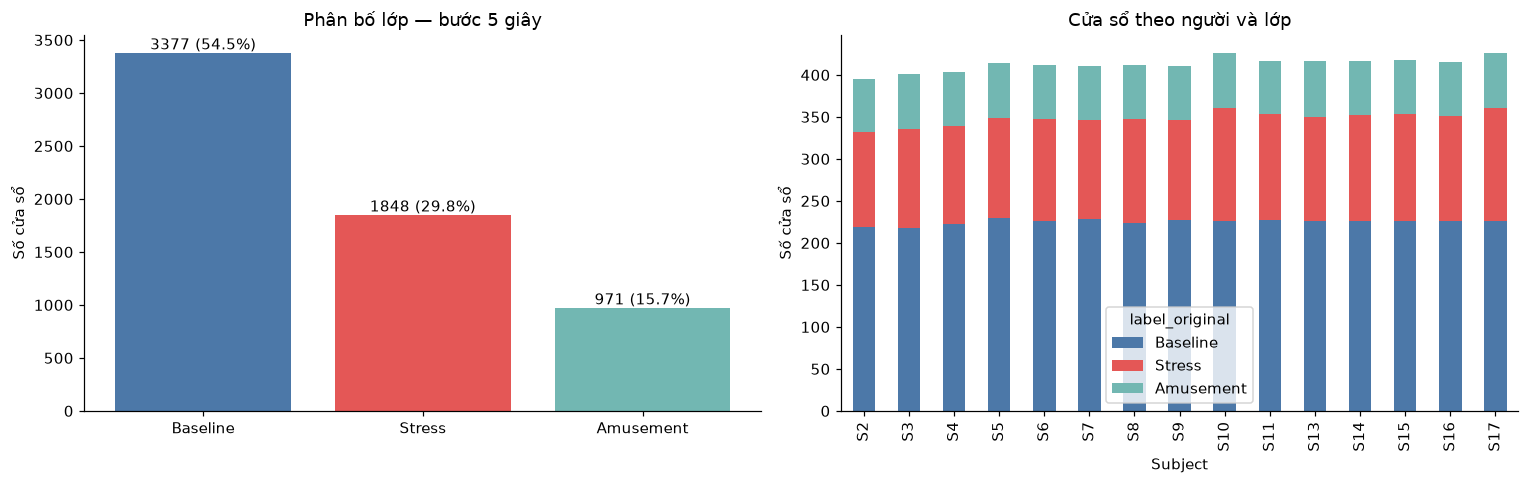

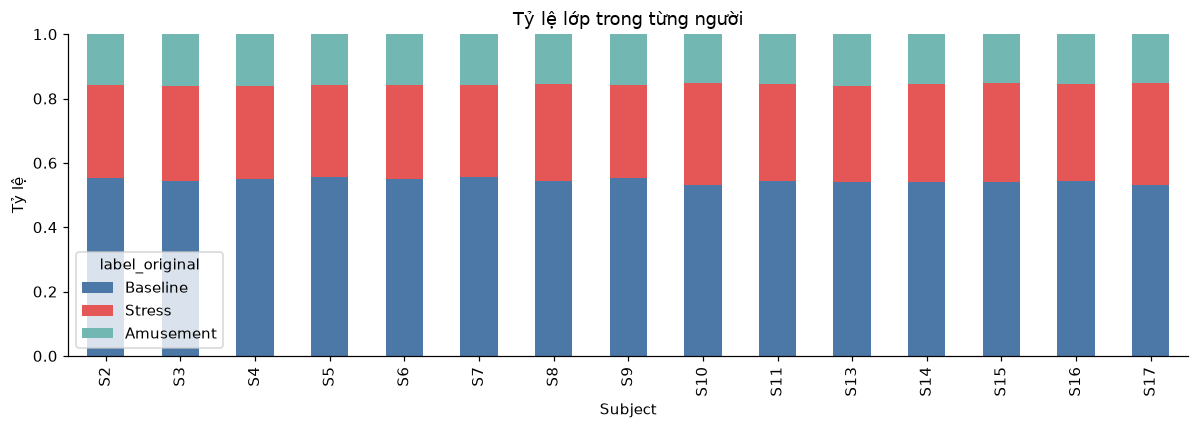

In [5]:
label_counts = df.label_original.value_counts().reindex([1,2,3], fill_value=0)
label_table = pd.DataFrame({'label_original':label_counts.index,
                            'class_name':[LABEL_NAMES[i] for i in label_counts.index],
                            'n_windows':label_counts.values})
label_table['percent'] = 100 * label_table.n_windows / len(df)
subject_label = pd.crosstab(df.subject_id, df.label_original).reindex(index=subject_order, columns=[1,2,3], fill_value=0)
subject_table = subject_label.rename(columns=LABEL_NAMES).copy()
subject_table['total'] = subject_table.sum(axis=1)
subject_table.index.name = 'subject_id'
display(label_table)
display(subject_table)
save_table(label_table, 'label_distribution.csv')
save_table(subject_table, 'windows_by_subject_and_label.csv', index=True)
if (subject_label == 0).any().any():
    warnings.warn('Có subject thiếu ít nhất một lớp; cần ghi rõ khi đánh giá LOSO.')

fig, axes = plt.subplots(1,2,figsize=(14,4.5))
axes[0].bar(label_table.class_name, label_table.n_windows, color=COLORS)
axes[0].set(title='Phân bố lớp — bước 5 giây', ylabel='Số cửa sổ')
for i, row in label_table.iterrows():
    axes[0].text(i, row.n_windows, f'{row.n_windows} ({row.percent:.1f}%)', ha='center', va='bottom')
subject_label.rename(columns=LABEL_NAMES).plot.bar(stacked=True, ax=axes[1], color=COLORS)
axes[1].set(title='Cửa sổ theo người và lớp', xlabel='Subject', ylabel='Số cửa sổ')
save_figure(fig, '01_label_subject_distribution.png')
fig, ax = plt.subplots(figsize=(11,4))
subject_label.div(subject_label.sum(axis=1), axis=0).rename(columns=LABEL_NAMES).plot.bar(stacked=True, ax=ax, color=COLORS)
ax.set(title='Tỷ lệ lớp trong từng người', xlabel='Subject', ylabel='Tỷ lệ', ylim=(0,1))
save_figure(fig, '02_class_proportions_by_subject.png')


## 4. Chất lượng dữ liệu
Kiểm tra NaN, Inf, khóa trùng, cột hằng và cờ chất lượng. Cờ
`finite_only_not_physiological_QA` chỉ cho biết kiểm tra tính hữu hạn,
không xác nhận tín hiệu đạt chất lượng sinh lý. Không tự điền thiếu hoặc xóa mẫu.


In [6]:
values = df[feature_cols].to_numpy(dtype=float)
quality = pd.DataFrame({'feature':feature_cols,
    'nan_count':np.isnan(values).sum(axis=0),
    'inf_count':np.isinf(values).sum(axis=0),
    'n_unique_finite':[df[c].replace([np.inf,-np.inf],np.nan).nunique() for c in feature_cols]})
quality['nan_percent'] = 100 * quality.nan_count / len(df)
quality['constant_or_all_missing'] = quality.n_unique_finite <= 1
duplicates = df[df.duplicated(['subject_id','window_id'], keep=False)].copy()
quality_subject = df[['subject_id']].copy()
quality_subject['n_windows'] = 1
quality_subject['rows_with_nan'] = np.isnan(values).any(axis=1).astype(int)
quality_subject['rows_with_inf'] = np.isinf(values).any(axis=1).astype(int)
quality_subject['duplicate_key_rows'] = df.duplicated(['subject_id','window_id'],keep=False).astype(int)
quality_subject = quality_subject.groupby('subject_id').sum().reindex(subject_order)
flags = df.groupby(['subject_id','quality_flag'],dropna=False).size().rename('n_windows').reset_index()
display(quality)
display(quality_subject)
display(flags)
print('Số dòng thuộc nhóm khóa trùng:', len(duplicates))
save_table(quality, 'feature_quality.csv')
save_table(quality_subject, 'quality_by_subject.csv', index=True)
save_table(flags, 'quality_flags.csv')
save_table(duplicates, 'duplicate_keys.csv')
if len(duplicates) or np.isinf(values).any():
    warnings.warn('Có khóa trùng hoặc Inf: cần điều tra trước khi huấn luyện.')


,feature,nan_count,inf_count,n_unique_finite,nan_percent,constant_or_all_missing
0,ecg_mean,0,0,6175,0.0,False
1,ecg_std,0,0,6196,0.0,False
2,ecg_min,0,0,1099,0.0,False
3,ecg_max,0,0,334,0.0,False
4,ecg_rms,0,0,6196,0.0,False
5,ecg_iqr,0,0,3998,0.0,False
6,ecg_range,0,0,1628,0.0,False
7,eda_mean,0,0,6196,0.0,False
8,eda_std,0,0,6196,0.0,False
9,eda_min,0,0,1563,0.0,False


,n_windows,rows_with_nan,rows_with_inf,duplicate_key_rows
subject_id,,,,
S2,395,0,0,0
S3,401,0,0,0
S4,404,0,0,0
S5,414,0,0,0
S6,412,0,0,0
S7,411,0,0,0
S8,412,0,0,0
S9,411,0,0,0
S10,426,0,0,0


,subject_id,quality_flag,n_windows
0,S10,finite_only_not_physiological_QA,426
1,S11,finite_only_not_physiological_QA,417
2,S13,finite_only_not_physiological_QA,417
3,S14,finite_only_not_physiological_QA,417
4,S15,finite_only_not_physiological_QA,418
5,S16,finite_only_not_physiological_QA,415
6,S17,finite_only_not_physiological_QA,426
7,S2,finite_only_not_physiological_QA,395
8,S3,finite_only_not_physiological_QA,401
9,S4,finite_only_not_physiological_QA,404


Số dòng thuộc nhóm khóa trùng: 0


## 5. Thống kê mô tả, phân bố và điểm cực trị
Biểu đồ dùng giá trị hữu hạn; NaN/Inf vẫn được báo cáo ở mục 4 và bảng gốc
không bị thay đổi. Quy tắc IQR chỉ đánh dấu điểm xa phân bố chung để xem xét;
khác biệt giữa người/trạng thái có thể hợp lệ, không tự loại những điểm này.


,count,mean,std,min,25%,50%,75%,max
ecg_mean,6196.0,0.001097,0.000487,-0.005041,0.000887,0.001143,0.001375,0.004059
ecg_std,6196.0,0.262977,0.064193,0.108775,0.230182,0.267133,0.298716,0.476600
ecg_min,6196.0,-0.634091,0.245772,-1.500000,-0.782913,-0.576141,-0.446457,-0.211487
ecg_max,6196.0,1.426842,0.189066,0.765060,1.496567,1.499222,1.499451,1.499954
ecg_rms,6196.0,0.262980,0.064192,0.108784,0.230186,0.267137,0.298716,0.476600
ecg_iqr,6196.0,0.136446,0.068868,0.043213,0.092926,0.130554,0.155869,0.521038
ecg_range,6196.0,2.060932,0.339188,1.043427,1.922379,2.038147,2.258709,2.999496
eda_mean,6196.0,4.586857,3.441755,0.582896,1.977062,3.717352,6.313281,20.056069
eda_std,6196.0,0.053523,0.100236,0.007504,0.013576,0.019127,0.046854,1.798704
eda_min,6196.0,4.343632,3.407617,0.000000,1.719666,3.514099,6.085682,19.797516


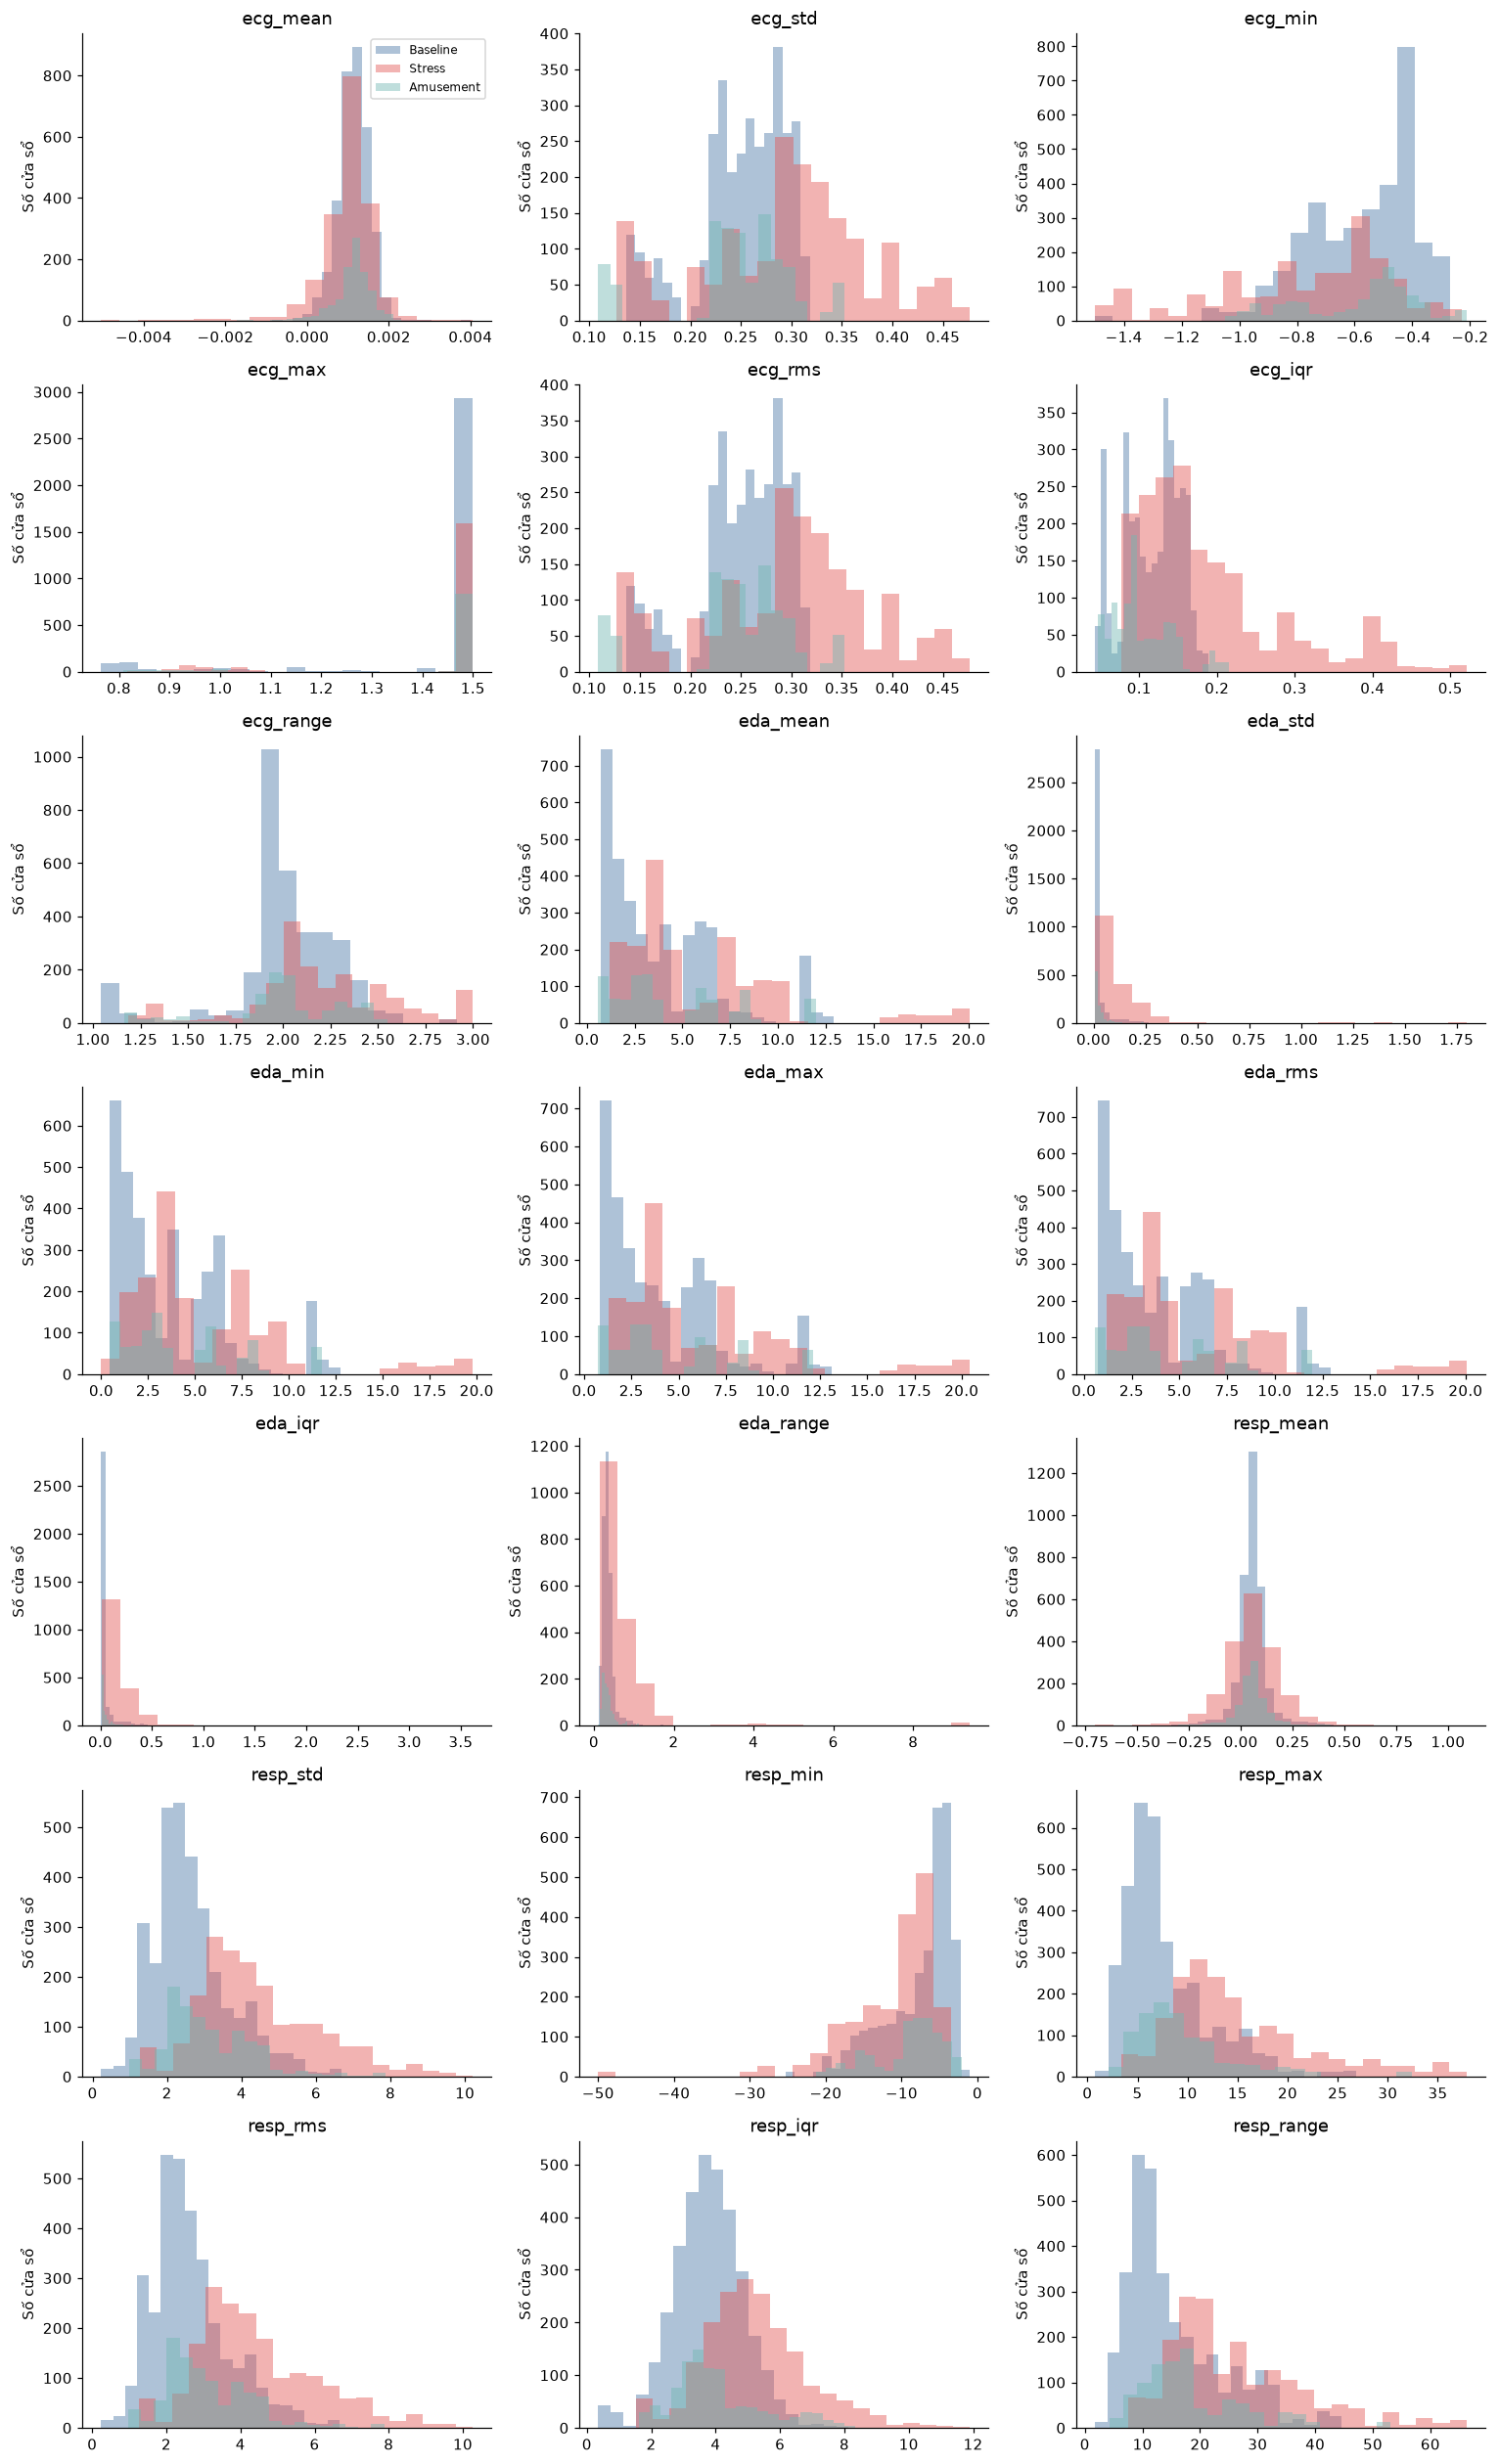

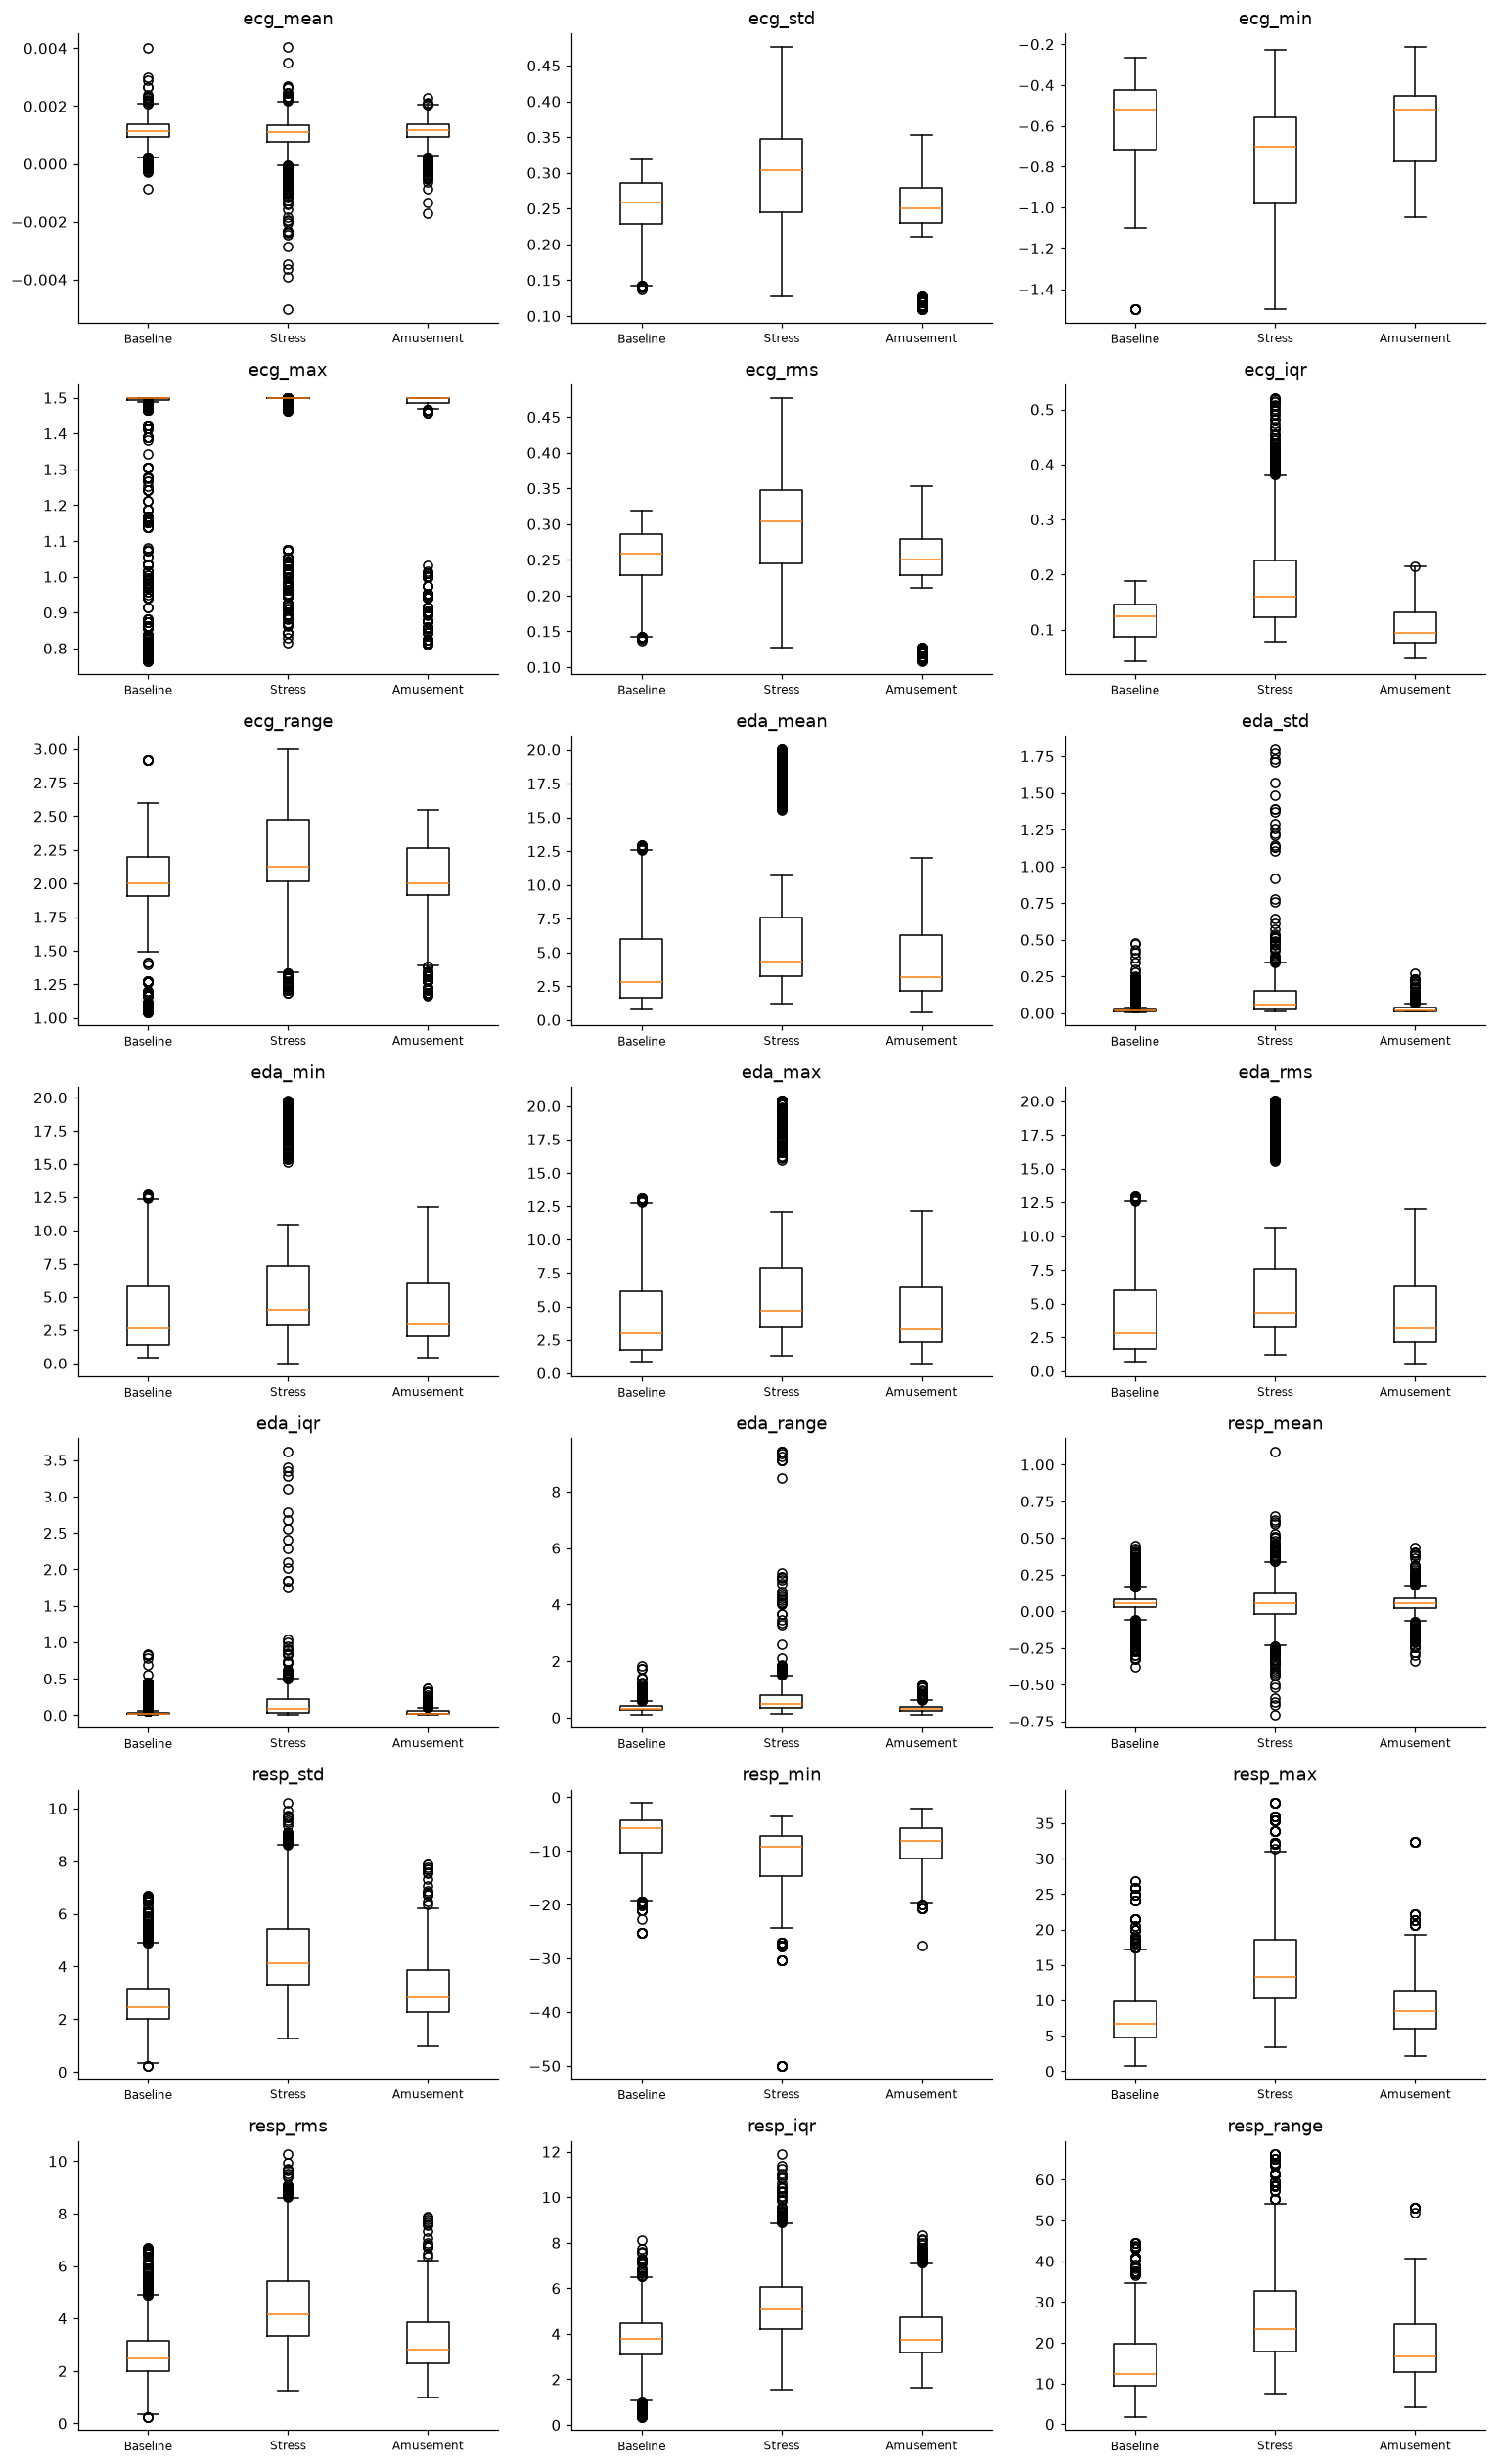

,feature,iqr,flagged_count,finite_count,flagged_percent
3,ecg_max,0.002884,1400,6196,22.595223
8,eda_std,0.033278,972,6196,15.687540
12,eda_iqr,0.052643,917,6196,14.799871
13,eda_range,0.185394,663,6196,10.700452
14,resp_mean,0.073668,625,6196,10.087153
6,ecg_range,0.336330,576,6196,9.296320
5,ecg_iqr,0.062943,365,6196,5.890897
1,ecg_std,0.068534,297,6196,4.793415
4,ecg_rms,0.068530,297,6196,4.793415
0,ecg_mean,0.000489,261,6196,4.212395


OSError: Cannot save file into a non-existent directory: 'c:\Users\thanh\source\repos\ML\Machine-learning\wesad-stress-detection\reports\tables\eda_step5'

In [7]:
finite = df[feature_cols].replace([np.inf,-np.inf],np.nan)
description = finite.describe().T
save_table(description, 'feature_descriptive_statistics.csv', index=True)
display(description)
by_label = finite.assign(label_original=df.label_original).groupby('label_original').agg(['count','mean','std','median'])
by_label.columns = ['__'.join(col) for col in by_label.columns]
save_table(by_label, 'feature_statistics_by_label.csv', index=True)

fig, axes = plt.subplots(7,3,figsize=(14,23))
for ax, col in zip(axes.flat, feature_cols):
    for label, color in zip([1,2,3], COLORS):
        x = finite.loc[df.label_original == label,col].dropna()
        if len(x):
            ax.hist(x, bins=20, alpha=.45, color=color, label=LABEL_NAMES[label])
    ax.set(title=col, ylabel='Số cửa sổ')
axes.flat[0].legend(fontsize=8)
save_figure(fig, '03_histograms_by_label.png')

fig, axes = plt.subplots(7,3,figsize=(14,23))
for ax, col in zip(axes.flat, feature_cols):
    groups = [finite.loc[df.label_original == k,col].dropna().to_numpy() for k in [1,2,3]]
    ax.boxplot(groups, tick_labels=list(LABEL_NAMES.values()), showfliers=True)
    ax.set_title(col)
    ax.tick_params(axis='x',labelsize=8)
save_figure(fig, '04_boxplots_by_label.png')

q1, q3 = finite.quantile(.25), finite.quantile(.75)
iqr = q3 - q1
outlier_mask = finite.lt(q1 - 1.5*iqr) | finite.gt(q3 + 1.5*iqr)
outlier_table = pd.DataFrame({'feature':feature_cols, 'iqr':iqr.values,
    'flagged_count':outlier_mask.sum().values, 'finite_count':finite.notna().sum().values})
outlier_table['flagged_percent'] = 100*outlier_table.flagged_count/outlier_table.finite_count.replace(0,np.nan)
display(outlier_table.sort_values('flagged_count',ascending=False))
save_table(outlier_table, 'iqr_review_flags.csv')


## 6. Tương quan và khác biệt giữa người
Pearson mô tả liên hệ tuyến tính giữa đặc trưng, không chứng minh quan hệ
nhân quả. Không chọn/xóa cột dựa vào toàn bảng rồi báo kết quả test như một
đánh giá hoàn toàn độc lập; nếu chọn đặc trưng cho mô hình, thực hiện trong fold train.


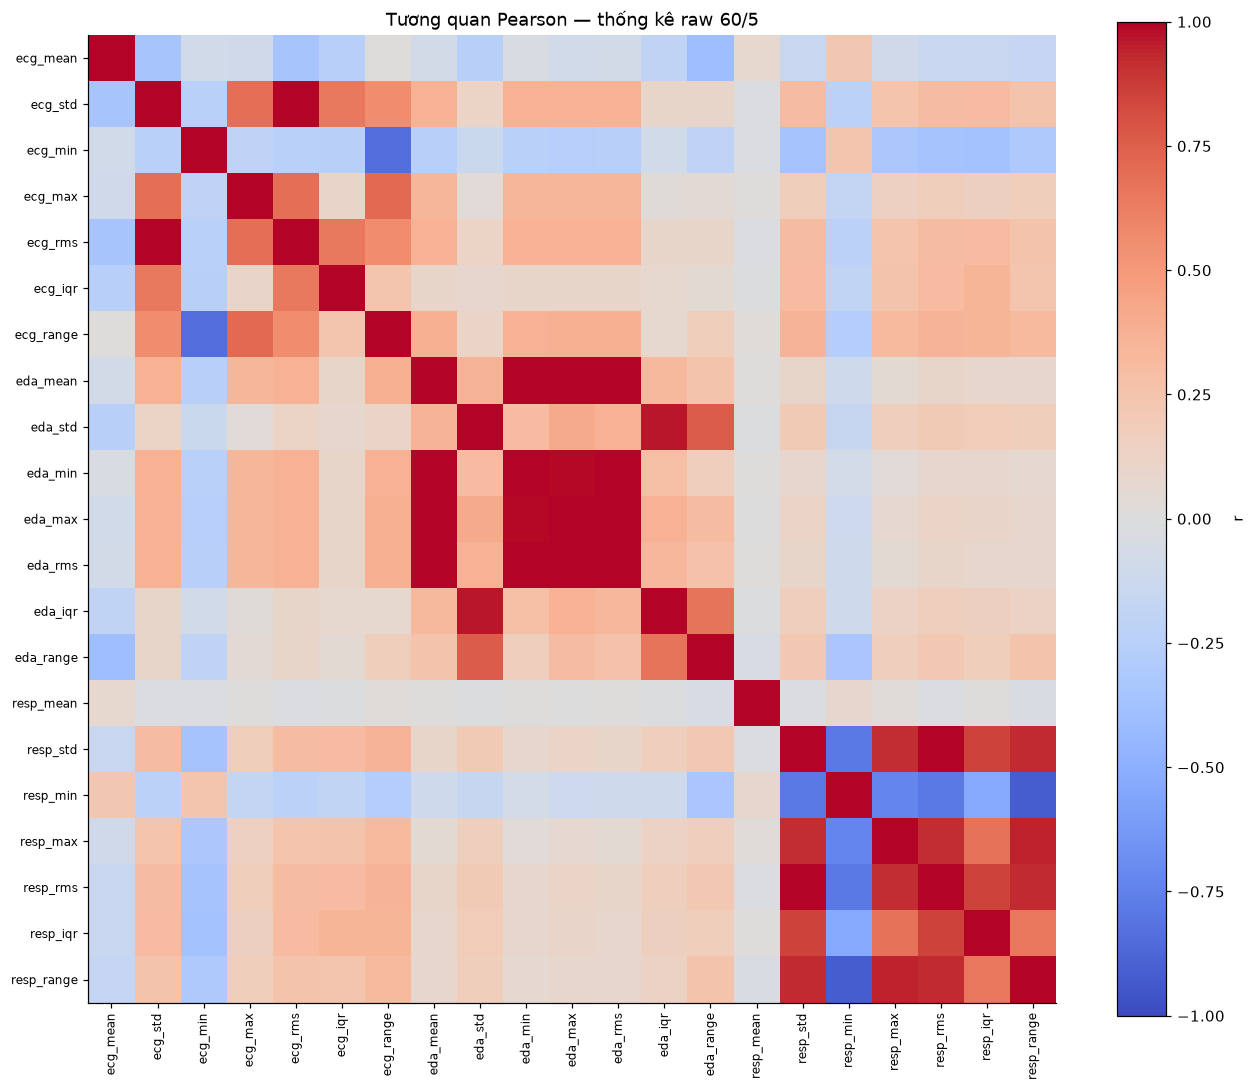

,feature_a,feature_b,pearson_r
0,ecg_std,ecg_rms,1.000000
1,eda_mean,eda_min,0.994022
2,eda_mean,eda_max,0.998334
3,eda_mean,eda_rms,0.999998
4,eda_std,eda_iqr,0.967829
5,eda_min,eda_max,0.989711
6,eda_min,eda_rms,0.993951
7,eda_max,eda_rms,0.998406
8,resp_std,resp_rms,0.999998


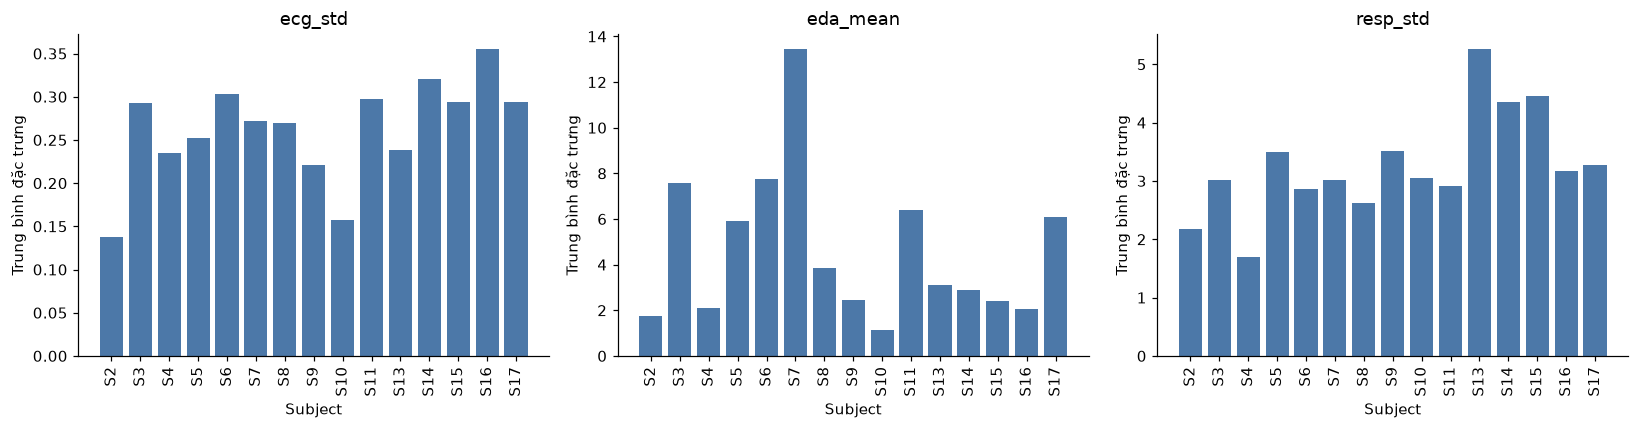

In [ ]:
corr = finite.corr(method='pearson')
save_table(corr, 'pearson_correlation.csv', index=True)
fig, ax = plt.subplots(figsize=(12,10))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(feature_cols)), feature_cols, fontsize=8)
ax.set_title('Tương quan Pearson — thống kê raw 60/5')
fig.colorbar(im, ax=ax, label='r')
save_figure(fig, '05_pearson_heatmap.png')
pairs = [{'feature_a':a,'feature_b':b,'pearson_r':corr.loc[a,b]}
         for i,a in enumerate(feature_cols) for b in feature_cols[i+1:]
         if pd.notna(corr.loc[a,b]) and abs(corr.loc[a,b]) >= .95]
high_corr = pd.DataFrame(pairs, columns=['feature_a','feature_b','pearson_r'])
display(high_corr)
save_table(high_corr, 'high_correlation_pairs.csv')
subject_means = finite.assign(subject_id=df.subject_id).groupby('subject_id').mean().reindex(subject_order)
save_table(subject_means, 'mean_features_by_subject.csv', index=True)
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, col in zip(axes, ['ecg_std','eda_mean','resp_std']):
    ax.bar(subject_order, subject_means[col], color='#4c78a8')
    ax.set(title=col, xlabel='Subject', ylabel='Trung bình đặc trưng')
    ax.tick_params(axis='x',rotation=90)
save_figure(fig, '06_subject_differences.png')


## 7. Khảo sát tín hiệu thô

Phần này độc lập với bước trượt và giữ nguyên cách khảo sát ECG/EDA/ACC.
`RUN_RAW_EDA = True` sẽ đọc lần lượt các PKL; đường dẫn lấy từ
`configs/local.yaml` hoặc `RAW_ROOT_OVERRIDE` trong ô dưới.
Chỉ mở PKL WESAD tin cậy. Có thể đặt False nếu chỉ cần chạy lại EDA feature.
Không coi phần raw đã hoàn tất nếu chưa có kết quả hoặc bị thiếu subject.


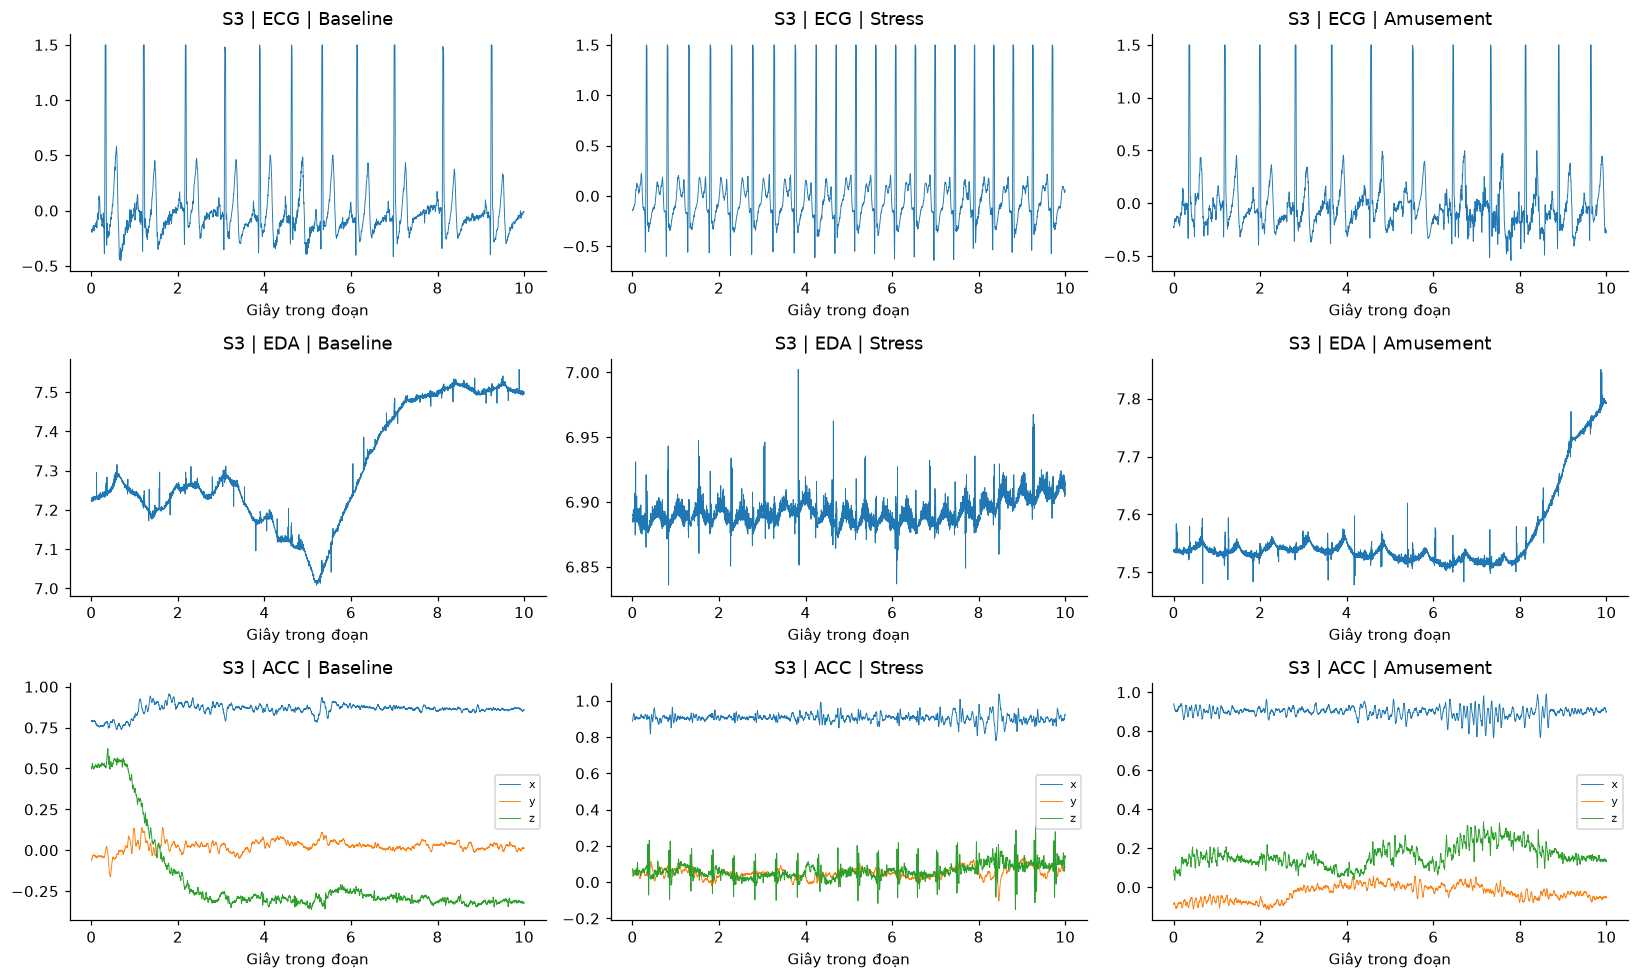

,subject_id,label,n_samples,seconds_at_700hz
0,S2,0,2142701,3061.001429
1,S2,1,800800,1144.000000
2,S2,2,430500,615.000000
3,S2,3,253400,362.000000
4,S2,4,537599,767.998571
...,...,...,...,...
114,S17,3,260400,372.000000
115,S17,4,511700,731.000000
116,S17,5,40600,58.000000
117,S17,6,41299,58.998571


,subject_id,sensor,shape,nan_values,inf_values,length_matches_labels
0,S2,ECG,"(4255300, 1)",0,0,True
1,S2,EDA,"(4255300, 1)",0,0,True
2,S2,ACC,"(4255300, 3)",0,0,True
3,S3,ECG,"(4545100, 1)",0,0,True
4,S3,EDA,"(4545100, 1)",0,0,True
5,S3,ACC,"(4545100, 3)",0,0,True
6,S4,ECG,"(4496100, 1)",0,0,True
7,S4,EDA,"(4496100, 1)",0,0,True
8,S4,ACC,"(4496100, 3)",0,0,True
9,S5,ECG,"(4380600, 1)",0,0,True


In [ ]:
RUN_RAW_EDA = True
RAW_ROOT_OVERRIDE = None  # Ví dụ: r'D:/Datasets/WESAD/WESAD'
RAW_ROOT = PROJECT_ROOT / 'data/raw/WESAD/WESAD'
if RAW_ROOT_OVERRIDE:
    RAW_ROOT = Path(RAW_ROOT_OVERRIDE).expanduser().resolve()
elif RUN_RAW_EDA and (PROJECT_ROOT / 'configs/local.yaml').is_file():
    import yaml
    local_config = yaml.safe_load((PROJECT_ROOT / 'configs/local.yaml').read_text(encoding='utf-8'))
    if not isinstance(local_config, dict) or not local_config.get('data_root'):
        raise ValueError('configs/local.yaml cần có data_root.')
    raw_path = Path(local_config['data_root']).expanduser()
    RAW_ROOT = raw_path if raw_path.is_absolute() else (PROJECT_ROOT / raw_path).resolve()
raw_label_table = None
raw_quality_table = None
RAW_SUBJECTS = EXPECTED_SUBJECTS
ILLUSTRATION_SUBJECT = 'S3'

if RUN_RAW_EDA:
    import pickle
    import gc
    raw_labels, raw_quality = [], []
    for subject in RAW_SUBJECTS:
        path = RAW_ROOT / subject / f'{subject}.pkl'
        if not path.is_file():
            warnings.warn(f'Bỏ qua file không có: {path}')
            continue
        with path.open('rb') as f:
            raw = pickle.load(f, encoding='latin1')
        labels = np.asarray(raw['label']).reshape(-1)
        unique, counts = np.unique(labels, return_counts=True)
        raw_labels.extend({'subject_id':subject,'label':int(k),'n_samples':int(v),
                           'seconds_at_700hz':int(v)/700} for k,v in zip(unique,counts))
        chest = raw['signal']['chest']
        for sensor in ['ECG','EDA','ACC']:
            x = np.asarray(chest[sensor])
            raw_quality.append({'subject_id':subject,'sensor':sensor,'shape':str(x.shape),
                'nan_values':int(np.isnan(x).sum()),'inf_values':int(np.isinf(x).sum()),
                'length_matches_labels':len(x)==len(labels)})
        if subject == ILLUSTRATION_SUBJECT:
            n = 10*700
            fig, axes = plt.subplots(3,3,figsize=(15,9))
            for j, label in enumerate([1,2,3]):
                mask = labels == label
                edges = np.diff(np.r_[False,mask,False].astype(int))
                starts, ends = np.flatnonzero(edges==1), np.flatnonzero(edges==-1)
                starts = starts[(ends-starts)>=n]
                for i,sensor in enumerate(['ECG','EDA','ACC']):
                    ax = axes[i,j]
                    ax.set_title(f'{subject} | {sensor} | {LABEL_NAMES[label]}')
                    ax.set_xlabel('Giây trong đoạn')
                    if not len(starts):
                        ax.text(.5,.5,'Không có đoạn đủ 10 giây',ha='center',transform=ax.transAxes)
                        continue
                    start = int(starts[0])
                    segment = np.asarray(chest[sensor])[start:start+n]
                    ax.plot(np.arange(len(segment))/700, segment, linewidth=.6)
                    if sensor == 'ACC':
                        ax.legend(['x','y','z'],fontsize=7)
            save_figure(fig, f'07_raw_signals_{subject}.png')
        del raw, chest
        gc.collect()
    if not raw_labels:
        raise FileNotFoundError('Không đọc được PKL nào; kiểm tra RAW_ROOT.')
    raw_label_table = pd.DataFrame(raw_labels)
    raw_quality_table = pd.DataFrame(raw_quality)
    display(raw_label_table)
    display(raw_quality_table)
    save_table(raw_label_table, 'raw_label_distribution.csv')
    save_table(raw_quality_table, 'raw_signal_quality.csv')
else:
    print('Chưa chạy khảo sát tín hiệu thô. Bật RUN_RAW_EDA khi có PKL và cần bổ sung G1.')


## 8. Tóm tắt tự động và lưu thông tin lần chạy


In [ ]:
nonzero = label_counts[label_counts>0]
ratio = float(nonzero.max()/nonzero.min()) if len(nonzero)==3 else None
summary = {
    'created_at_utc':datetime.now(timezone.utc).isoformat(),
    'input_file':str(FEATURE_PATH),
    'input_sha256':hashlib.sha256(FEATURE_PATH.read_bytes()).hexdigest(),
    'scope':'chest raw statistics; window 60s; step 5s; majority >=0.90',
    'processing_metadata_verified':processing is not None,
    'processing':processing,
    'n_windows':len(df),'n_subjects':len(subject_order),'n_features':len(feature_cols),
    'subjects':subject_order, 'missing_subjects':missing_subjects,
    'label_counts':{str(k):int(v) for k,v in label_counts.items()},
    'largest_smallest_class_ratio':ratio,
    'nan_feature_values':int(np.isnan(values).sum()),
    'inf_feature_values':int(np.isinf(values).sum()),
    'duplicate_key_rows':len(duplicates),
    'constant_or_all_missing_features':quality.loc[quality.constant_or_all_missing,'feature'].tolist(),
    'window_seconds':WINDOW_SECONDS, 'step_seconds':STEP_SECONDS,
    'label_rule':'majority', 'min_label_fraction':MIN_LABEL_FRACTION,
    'observed_min_label_fraction':float(df.label_fraction.min()),
    'observed_max_label_fraction':float(df.label_fraction.max()),
    'raw_eda_enabled':RUN_RAW_EDA,
    'raw_subjects_checked':sorted(raw_label_table.subject_id.unique().tolist()) if raw_label_table is not None else [],
    'interpretation_limit':'Exploratory full-table analysis; no model performance or physiological QA claim.'
}
(TABLE_DIR / 'eda_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print(f'Có {len(df)} cửa sổ từ {len(subject_order)} người, với {len(feature_cols)} đặc trưng.')
print('Số mẫu Baseline/Stress/Amusement:', label_counts.tolist())
print('Tỷ lệ lớp lớn nhất / nhỏ nhất:', round(ratio,2) if ratio is not None else 'Thiếu ít nhất một lớp')
print('NaN:', summary['nan_feature_values'], '| Inf:', summary['inf_feature_values'], '| Dòng khóa trùng:',len(duplicates))


print('Bảng:', TABLE_DIR)
print('Hình:', FIG_DIR)


Có 6196 cửa sổ từ 15 người, với 21 đặc trưng.
Số mẫu Baseline/Stress/Amusement: [3377, 1848, 971]
Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.48
NaN: 0 | Inf: 0 | Dòng khóa trùng: 0
Bảng: c:\Users\thanh\source\repos\ML\Machine-learning\wesad-stress-detection\reports\tables\eda_step5
Hình: c:\Users\thanh\source\repos\ML\Machine-learning\wesad-stress-detection\reports\figures\eda_step5


## 9. Nhận xét theo kết quả bộ 60/5

Ô dưới tạo nhận xét từ dữ liệu vừa chạy và lưu `eda_observations.md`.
Không dùng số liệu 513 cửa sổ hay tỷ lệ lớp của bộ 60/60 cũ.
Sau khi xem hình, bổ sung diễn giải hình dạng phân bố/tín hiệu; nhận xét
tự động không thay thế kiểm tra chất lượng sinh lý hoặc kết quả mô hình.


In [ ]:
from IPython.display import Markdown
lines = [
    '## Nhận xét EDA — cửa sổ 60 giây, bước 5 giây',
    '',
    f'Bảng hiện có **{len(df):,} cửa sổ**, **{len(subject_order)} người** và **{len(feature_cols)} đặc trưng** thống kê raw ECG/EDA/Resp ngực.',
    'Cấu hình mục tiêu là majority ≥90%. Có thể có tối đa 10% mẫu khác nhãn trong cửa sổ hợp lệ.',
    ('Đã đối chiếu cấu hình trích xuất từ config.json; đây là kiểm tra metadata, chưa tính lại feature/nhãn từ PKL.' if processing is not None else
     '**Hạn chế:** thiếu config.json; lưới thời gian và tỷ lệ nhãn trong CSV chưa đủ xác minh cấu hình tạo dữ liệu.'),
    '', '### Phân bố lớp',
]
for row in label_table.itertuples(index=False):
    lines.append(f'- {row.class_name}: {row.n_windows:,} cửa sổ ({row.percent:.2f}%).')
lines.append(f'Số cửa sổ theo người dao động {int(subject_table.total.min())}–{int(subject_table.total.max())}.')
if ratio is not None:
    lines.append(f'Tỷ lệ số cửa sổ lớp lớn nhất/nhỏ nhất là {ratio:.2f}.')
missing_class_subjects = subject_label.index[(subject_label == 0).any(axis=1)].tolist()
lines.append('Các subject thiếu ít nhất một lớp: ' + (', '.join(missing_class_subjects) if missing_class_subjects else 'không có trong bảng hiện tại') + '.')
if missing_subjects or extra_subjects:
    lines.append(f'**Phạm vi chưa khớp 15 người:** thiếu {missing_subjects}; ngoài danh sách {extra_subjects}.')
lines.extend(['', '### Chất lượng và điểm cần kiểm tra',
    f'Có {summary["nan_feature_values"]} giá trị NaN, {summary["inf_feature_values"]} giá trị Inf và {len(duplicates)} dòng thuộc nhóm khóa trùng.',
    f'Cột hằng/thiếu toàn bộ: {summary["constant_or_all_missing_features"]}.',
    f'label_fraction quan sát từ {df.label_fraction.min():.4f} đến {df.label_fraction.max():.4f}.',
    'quality_flag phản ánh phạm vi kiểm tra của extractor; tính hữu hạn không chứng minh chất lượng sinh lý.'])
for row in outlier_table.sort_values('flagged_count',ascending=False).head(3).itertuples(index=False):
    lines.append(f'- {row.feature}: {row.flagged_count} giá trị bị đánh dấu IQR ({row.flagged_percent:.2f}% trên giá trị hữu hạn).')
lines.append('Đánh dấu IQR phục vụ xem xét; chưa tự loại cửa sổ hoặc kết luận đó là lỗi.')
lines.extend(['', '### Tương quan'])
if high_corr.empty:
    lines.append('Không có cặp đạt |r| ≥0.95 trong bảng hiện tại.')
else:
    for row in high_corr.reindex(high_corr.pearson_r.abs().sort_values(ascending=False).index).head(5).itertuples(index=False):
        lines.append(f'- {row.feature_a} và {row.feature_b}: r = {row.pearson_r:.6f}.')
lines.append('Nếu chọn đặc trưng cho mô hình, học lựa chọn trong train của từng fold; không chọn trên toàn bảng rồi báo điểm test như đánh giá độc lập.')
lines.extend(['', '### Tín hiệu thô'])
if raw_quality_table is not None:
    checked = sorted(raw_quality_table.subject_id.unique().tolist())
    lines.append(f'Đã kiểm tra {len(checked)} người và {len(raw_quality_table)} cặp người–tín hiệu ECG/EDA/ACC trong lần chạy này.')
    lines.append(f'Tổng NaN: {int(raw_quality_table.nan_values.sum())}; tổng Inf: {int(raw_quality_table.inf_values.sum())}; số cặp sai độ dài so với nhãn: {int((~raw_quality_table.length_matches_labels).sum())}.')
    missing_raw = sorted(set(RAW_SUBJECTS) - set(checked))
    if missing_raw:
        lines.append(f'Chưa khảo sát raw của: {missing_raw}.')
else:
    lines.append('Không chạy khảo sát raw trong lần chạy này; không khẳng định đã kiểm tra đủ tín hiệu thô.')
lines.extend(['', '### Hướng mô hình hóa',
    'Chỉ dùng 21 feature làm X; giữ subject_id cho outer LOSO, không đưa metadata hoặc nhãn vào X.',
    'Stress là lớp 1 trong bài toán nhị phân; Baseline và Amusement là Non-stress (0).',
    'Imputer/scaler/selection/resampling học trong train của từng fold. Tuning chỉ dùng subject thuộc outer train.',
    'Cửa sổ liên tiếp chồng lấn 55 giây, không coi chúng là quan sát độc lập. Không chia ngẫu nhiên các dòng train/test.',
    'EDA không chứng minh hiệu năng hay khả năng khái quát của KNN/SVM. Báo cáo giữa kỳ tiếp tục bổ sung baseline và mô hình mặc định; tuning và kiểm định theo kế hoạch nhóm.'])
observations = '\n\n'.join(lines)
(TABLE_DIR / 'eda_observations.md').write_text(observations, encoding='utf-8')
display(Markdown(observations))


## Nhận xét EDA — cửa sổ 60 giây, bước 5 giây



Bảng hiện có **6,196 cửa sổ**, **15 người** và **21 đặc trưng** thống kê raw ECG/EDA/Resp ngực.

Cấu hình mục tiêu là majority ≥90%. Có thể có tối đa 10% mẫu khác nhãn trong cửa sổ hợp lệ.

Đã đối chiếu cấu hình trích xuất từ config.json; đây là kiểm tra metadata, chưa tính lại feature/nhãn từ PKL.



### Phân bố lớp

- Baseline: 3,377 cửa sổ (54.50%).

- Stress: 1,848 cửa sổ (29.83%).

- Amusement: 971 cửa sổ (15.67%).

Số cửa sổ theo người dao động 395–426.

Tỷ lệ số cửa sổ lớp lớn nhất/nhỏ nhất là 3.48.

Các subject thiếu ít nhất một lớp: không có trong bảng hiện tại.



### Chất lượng và điểm cần kiểm tra

Có 0 giá trị NaN, 0 giá trị Inf và 0 dòng thuộc nhóm khóa trùng.

Cột hằng/thiếu toàn bộ: [].

label_fraction quan sát từ 0.9015 đến 1.0000.

quality_flag phản ánh phạm vi kiểm tra của extractor; tính hữu hạn không chứng minh chất lượng sinh lý.

- ecg_max: 1400 giá trị bị đánh dấu IQR (22.60% trên giá trị hữu hạn).

- eda_std: 972 giá trị bị đánh dấu IQR (15.69% trên giá trị hữu hạn).

- eda_iqr: 917 giá trị bị đánh dấu IQR (14.80% trên giá trị hữu hạn).

Đánh dấu IQR phục vụ xem xét; chưa tự loại cửa sổ hoặc kết luận đó là lỗi.



### Tương quan

- ecg_std và ecg_rms: r = 1.000000.

- eda_mean và eda_rms: r = 0.999998.

- resp_std và resp_rms: r = 0.999998.

- eda_max và eda_rms: r = 0.998406.

- eda_mean và eda_max: r = 0.998334.

Nếu chọn đặc trưng cho mô hình, học lựa chọn trong train của từng fold; không chọn trên toàn bảng rồi báo điểm test như đánh giá độc lập.



### Tín hiệu thô

Đã kiểm tra 15 người và 45 cặp người–tín hiệu ECG/EDA/ACC trong lần chạy này.

Tổng NaN: 0; tổng Inf: 0; số cặp sai độ dài so với nhãn: 0.



### Hướng mô hình hóa

Chỉ dùng 21 feature làm X; giữ subject_id cho outer LOSO, không đưa metadata hoặc nhãn vào X.

Stress là lớp 1 trong bài toán nhị phân; Baseline và Amusement là Non-stress (0).

Imputer/scaler/selection/resampling học trong train của từng fold. Tuning chỉ dùng subject thuộc outer train.

Cửa sổ liên tiếp chồng lấn 55 giây, không coi chúng là quan sát độc lập. Không chia ngẫu nhiên các dòng train/test.

EDA không chứng minh hiệu năng hay khả năng khái quát của KNN/SVM. Báo cáo giữa kỳ tiếp tục bổ sung baseline và mô hình mặc định; tuning và kiểm định theo kế hoạch nhóm.

## 10. Bàn giao

Sau khi chạy dữ liệu thật: lưu notebook có output, bảng và hình của `eda_step5`,
kèm `eda_summary.json` và `eda_observations.md`. Ghi đúng số subject đã có.
Không tự khẳng định hoàn tất G1–G3 chỉ vì notebook chạy xong.
Không cần so sánh bước 60 giây nếu nhóm đã thống nhất chỉ làm bước 5 giây.
